In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, Tensor
from torch.utils.data import DataLoader, TensorDataset
import rasterio
from typing import NamedTuple

from constants import SEED, DEFAULT_TILE_SIZE, CE_LOSS_IGNORE_INDEX
from grad_descent_train_eval import ExperimentRunner

np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [2]:
class FireLinearParams(NamedTuple):
    embed_dim: int
    num_categories: int = 1

    def __str__(self):
        return f"Lin(d={self.embed_dim}, out={self.num_categories})"


class FireLinear(nn.Module):
    def __init__(self, args: FireLinearParams):
        super().__init__()
        self.args = args
        self.net = nn.Linear(args.embed_dim, args.num_categories)

    def forward(self, X: Tensor):
        """
        Input: (batch, embed_dim, tile_rows, tile_cols)
        Output: (batch, num_categories, tile_rows, tile_cols)

        NOTE: nn.CrossEntropyLoss expects logits to be the second dimension.
        """
        X = X.permute(0, 2, 3, 1)
        logits = self.net(X)
        return logits.permute(0, 3, 1, 2)


In [3]:
DEFAULT_BATCH_SIZE = 256

def to_data_loader(
        X: np.ndarray,
        y: np.ndarray,
        shuffle: bool = False,
        batch_size: int = DEFAULT_BATCH_SIZE
    ) -> DataLoader:
    # nn.CrossEntropyLoss expects longs.
    dataset = TensorDataset(torch.Tensor(X), torch.Tensor(y).long())
    return DataLoader(dataset, shuffle=shuffle, batch_size=batch_size)

def load_surface_fuel_data(
        embeds_file: str,
        target_file: str,
        tile_size=DEFAULT_TILE_SIZE
) -> tuple[dict[int, int], np.ndarray, np.ndarray, DataLoader, DataLoader, DataLoader]:
    """
    Returns:
    - idx_to_class: Dictionary mapping a target label index back to its
      original numeric value.
    - X_tiles: (total_tiles, bands, tile_rows, tile_cols)
    - y_tiles: (total_tiles, tile_size, tile_size)
    - Each split feature matrix has shape:
        (num_tiles_in_split, bands, tile_rows, tile_cols)
    - And target matrix:
        (num_tiles_in_split, tile_rows, tile_cols)

    Each target_matrix contains indices of surface fuels. E.g., a value of 0
    corresponds to surface fuel code 99, which is "bare ground". This mapping
    is done because nn.CrossEntropyLoss expects values in the range [0, num_categories).
    """
    with rasterio.open(embeds_file) as src:
        X = src.read()                 # (bands, rows, cols)
    with rasterio.open(target_file) as src:
        y_orig = src.read().squeeze()  # (rows, cols)

    # Map fuel categories to indices for nn.CrossEntropyLoss.
    classes, y = np.unique(y_orig, return_inverse=True)
    idx_to_class = dict(enumerate(classes))
    assert y.shape == y_orig.shape

    # Full embeddings have NaN values. Map them to 0.0, but ignore them
    # in loss calculations.
    bad_pixels = ~np.isfinite(X).all(axis=0)
    y[bad_pixels] = CE_LOSS_IGNORE_INDEX
    X = np.where(np.isfinite(X), X, 0.0)

    # Select AOI that is evenly divisible by tile dimension, then select
    # train/val/test tiles.
    bands, rows, cols = X.shape
    n_rows = rows // tile_size
    n_cols = cols // tile_size
    X_cropped = X[:, :n_rows * tile_size, :n_cols * tile_size]
    y_cropped = y[:n_rows * tile_size, :n_cols * tile_size]

    X_tiles = X_cropped.reshape(bands, n_rows, tile_size, n_cols, tile_size)
    X_tiles = X_tiles.transpose(1, 3, 0, 2, 4).reshape(-1, bands, tile_size, tile_size)
    y_tiles = y_cropped.reshape(n_rows, tile_size, n_cols, tile_size)
    y_tiles = y_tiles.transpose(0, 2, 1, 3).reshape(-1, tile_size, tile_size)

    PATTERN = np.array([[1, 1, 1],
                        [1, 2, 3]], dtype="uint8")

    tile_r = np.arange(n_rows)[:, None] % PATTERN.shape[0]
    tile_c = np.arange(n_cols)[None, :] % PATTERN.shape[1]
    tile_split = PATTERN[tile_r, tile_c].ravel()  # (total_tiles,)

    train = to_data_loader(X_tiles[tile_split == 1], y_tiles[tile_split == 1], shuffle=True)
    val = to_data_loader(X_tiles[tile_split == 2], y_tiles[tile_split == 2])
    test = to_data_loader(X_tiles[tile_split == 3], y_tiles[tile_split == 3])

    return idx_to_class, X_tiles, y_tiles, train, val, test

## Model trained on quantized embeddings

In [ ]:
(
    idx_to_surface_fuel_cat,
    X,
    y,
    quant_train_loader,
    quant_val_loader,
    quant_test_loader
) = load_surface_fuel_data(
    "../../data/2022_foco_bbox_quant.tif",
    "../../data/surface_fuels_aligned.tif")
X.shape, y.shape

((6348, 128, 64, 64), (6348, 64, 64))

In [ ]:
batch_X, batch_y = next(iter(quant_train_loader))
batch_X.shape, batch_y.shape

(torch.Size([256, 128, 64, 64]), torch.Size([256, 64, 64]))

In [ ]:
num_surface_fuel_labels = len(idx_to_surface_fuel_cat)
print("Number of surface fuel categories in AOI =", num_surface_fuel_labels)

Number of surface fuel categories in AOI = 30


Running experiment: Lin(d=128, out=30)
epoch  1  train loss 29.265  val loss 20.694  (3s)
epoch  2  train loss 18.803  val loss 16.489  (2s)
epoch  3  train loss 15.515  val loss 14.030  (2s)
epoch  4  train loss 13.416  val loss 12.375  (2s)
epoch  5  train loss 12.009  val loss 11.256  (2s)
epoch  6  train loss 11.017  val loss 10.442  (2s)
epoch  7  train loss 10.269  val loss 9.783  (2s)
epoch  8  train loss 9.666  val loss 9.262  (2s)
epoch  9  train loss 9.170  val loss 8.819  (2s)
epoch 10  train loss 8.752  val loss 8.451  (2s)
epoch 11  train loss 8.393  val loss 8.121  (2s)
epoch 12  train loss 8.086  val loss 7.847  (2s)
epoch 13  train loss 7.812  val loss 7.591  (2s)
epoch 14  train loss 7.571  val loss 7.368  (2s)
epoch 15  train loss 7.354  val loss 7.167  (2s)
epoch 16  train loss 7.153  val loss 6.983  (2s)
epoch 17  train loss 6.970  val loss 6.814  (2s)
epoch 18  train loss 6.797  val loss 6.648  (2s)
epoch 19  train loss 6.639  val loss 6.500  (2s)
epoch 20  train l

,Classifier,Loss (val),Epochs,Param count
0,"Lin(d=128, out=30)",2.9897,120,3870


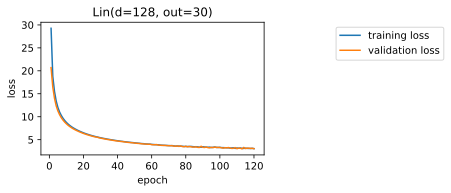

In [ ]:
runner1_1 = (
    ExperimentRunner(FireLinear)
        .with_lr(0.0001)
        .with_patience(10)
        .with_epochs(120)
        .with_data(quant_train_loader, quant_val_loader)
        .add_experiments(
            FireLinearParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
            )
        ).with_plots()
)

runner_results1_1 = runner1_1.run(verbosity=1)
runner_results1_1

# I ran this experiment before adding an accuracy measure to model evaluation.

## Model trained on full embeddings

In [4]:
(
    idx_to_surface_fuel_cat,
    X_full,
    y_full,
    full_train_loader,
    full_val_loader,
    full_test_loader
) = load_surface_fuel_data(
    "../../data/2022_foco_bbox_full_cog.tif",
    "../../data/surface_fuels_aligned.tif")
print("Loaded full data:", X_full.shape, y_full.shape)

Loaded full data: (6348, 128, 64, 64) (6348, 64, 64)


In [5]:
num_surface_fuel_labels = len(idx_to_surface_fuel_cat)
print("Number of surface fuel categories in AOI =", num_surface_fuel_labels)

Number of surface fuel categories in AOI = 30


In [18]:
print(f"Percent pixels ignored (NaN) = {float((y_full == -100).sum()) / y_full.size * 100.0:.4f}%")

Percent pixels ignored (NaN) = 0.0178%


Running experiment: Lin(d=128, out=30)
epoch  1  train loss 2.837  val loss 2.396  val acc 0.335(3s)
epoch  2  train loss 2.278  val loss 2.146  val acc 0.418(3s)
epoch  3  train loss 2.099  val loss 2.020  val acc 0.439(3s)
epoch  4  train loss 1.996  val loss 1.937  val acc 0.445(3s)
epoch  5  train loss 1.923  val loss 1.874  val acc 0.450(3s)
epoch  6  train loss 1.866  val loss 1.823  val acc 0.454(3s)
epoch  7  train loss 1.820  val loss 1.780  val acc 0.458(3s)
epoch  8  train loss 1.781  val loss 1.743  val acc 0.463(3s)
epoch  9  train loss 1.748  val loss 1.712  val acc 0.470(3s)
epoch 10  train loss 1.719  val loss 1.684  val acc 0.478(3s)
epoch 11  train loss 1.694  val loss 1.660  val acc 0.485(3s)
epoch 12  train loss 1.671  val loss 1.639  val acc 0.491(3s)
epoch 13  train loss 1.651  val loss 1.621  val acc 0.496(3s)
epoch 14  train loss 1.634  val loss 1.604  val acc 0.500(3s)
epoch 15  train loss 1.617  val loss 1.588  val acc 0.504(3s)
epoch 16  train loss 1.603  val

,Classifier,Loss (val),Epochs,Param count
0,"Lin(d=128, out=30)",1.2598,200,3870


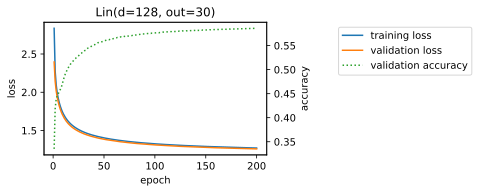

In [ ]:
runner2_2 = (
    ExperimentRunner(FireLinear)
        .with_lr(0.01)
        .with_patience(10)
        .with_epochs(200)
        .with_data(full_train_loader, full_val_loader)
        .add_experiments(
            FireLinearParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
            )
        ).with_plots()
)

runner_results2_2 = runner2_2.run(verbosity=1)
runner_results2_2

Running experiment: Lin(d=128, out=30)
epoch  1  train loss 2.088  val loss 1.702  val acc 0.466(3s)
epoch  2  train loss 1.641  val loss 1.553  val acc 0.501(3s)
epoch  3  train loss 1.534  val loss 1.516  val acc 0.516(3s)
epoch  4  train loss 1.528  val loss 1.435  val acc 0.543(3s)
epoch  5  train loss 1.429  val loss 1.390  val acc 0.555(3s)
epoch  6  train loss 1.402  val loss 1.375  val acc 0.561(3s)
epoch  7  train loss 1.414  val loss 1.350  val acc 0.564(3s)
epoch  8  train loss 1.358  val loss 1.344  val acc 0.566(3s)
epoch  9  train loss 1.361  val loss 1.341  val acc 0.560(3s)
epoch 10  train loss 1.377  val loss 1.334  val acc 0.557(3s)
epoch 11  train loss 1.340  val loss 1.315  val acc 0.573(3s)
epoch 12  train loss 1.324  val loss 1.319  val acc 0.565(3s)
epoch 13  train loss 1.360  val loss 1.385  val acc 0.509(3s)
epoch 14  train loss 1.317  val loss 1.291  val acc 0.578(3s)
epoch 15  train loss 1.298  val loss 1.279  val acc 0.581(3s)
epoch 16  train loss 1.292  val

,Classifier,Loss (val),Epochs,Param count
0,"Lin(d=128, out=30)",1.162,200,3870


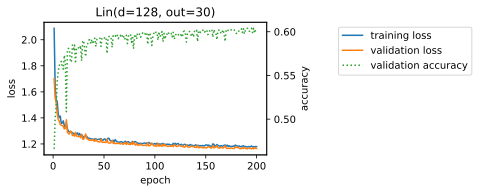

In [ ]:
runner2_3 = (
    ExperimentRunner(FireLinear)
        .with_lr(0.1)
        .with_patience(10)
        .with_epochs(200)
        .with_data(full_train_loader, full_val_loader)
        .add_experiments(
            FireLinearParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
            )
        ).with_plots()
)

runner_results2_3 = runner2_3.run(verbosity=1)
runner_results2_3

## Render predictions

### Quantized model

In [8]:
idx_to_fuel_code_lookup = torch.zeros(max(idx_to_surface_fuel_cat.keys()) + 1, dtype=torch.long, device=device)
for k, v in idx_to_surface_fuel_cat.items():
    idx_to_fuel_code_lookup[k] = v

In [ ]:
# Quantized embedding model: Render one tile prediction.
model = runner1_1.experiment_results[0].model.to(device)
val_sample_X, val_sample_y = next(iter(quant_val_loader))
val_sample_X, val_sample_y = val_sample_X[:1].to(device), val_sample_y[:1].to(device)

with torch.no_grad():
    predicted_tile = model(val_sample_X).argmax(dim=1)

In [10]:
predicted_tile.shape

torch.Size([1, 64, 64])

In [11]:
predicted_surface_fuel_codes = idx_to_fuel_code_lookup[predicted_tile]
true_surface_fuel_codes = idx_to_fuel_code_lookup[val_sample_y]

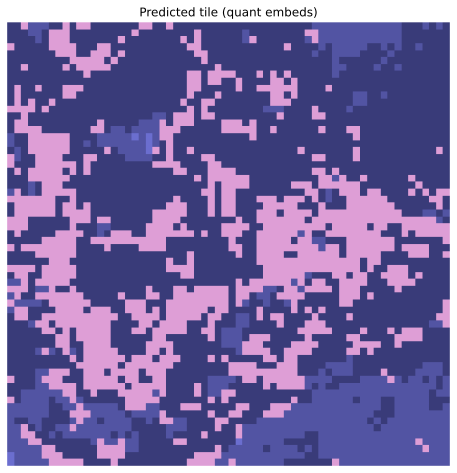

In [14]:
plt.figure(figsize=(10, 8))
plt.imshow(predicted_surface_fuel_codes.squeeze().cpu(), cmap="tab20b")
plt.title("Predicted tile (quant embeds)")
plt.axis("off")
plt.show();

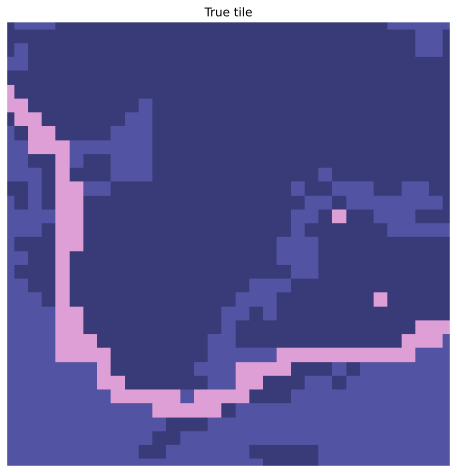

In [13]:
plt.figure(figsize=(10, 8))
plt.imshow(true_surface_fuel_codes.squeeze().cpu(), cmap="tab20b")
plt.title("True tile")
plt.axis("off")
plt.show();

### Full embedding model

In [ ]:
model = runner2_3.experiment_results[0].model.to(device)

In [ ]:
val_sample_X, val_sample_y = next(iter(full_val_loader))
val_sample_X, val_sample_y = val_sample_X[:1].to(device), val_sample_y[:1].to(device)

In [ ]:
with torch.no_grad():
    predicted_tile = model(val_sample_X).argmax(dim=1)

predicted_surface_fuel_codes_full = idx_to_fuel_code_lookup[predicted_tile]
true_surface_fuel_codes_full = idx_to_fuel_code_lookup[val_sample_y]

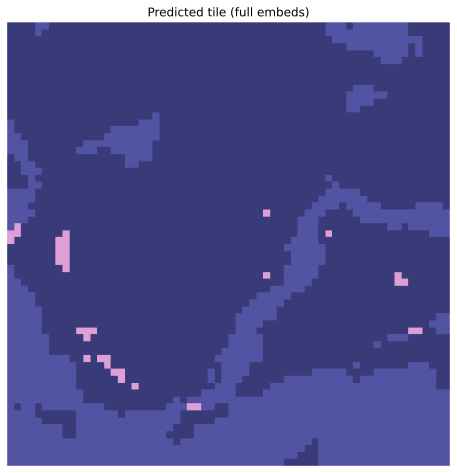

In [ ]:
plt.figure(figsize=(10, 8))
plt.imshow(predicted_surface_fuel_codes_full.squeeze().cpu(), cmap="tab20b")
plt.title("Predicted tile (full embeds)")
plt.axis("off")
plt.show();

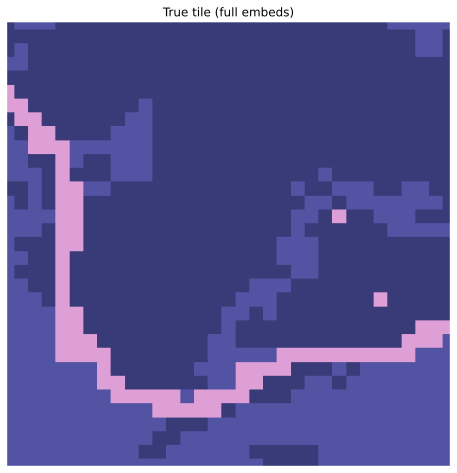

In [ ]:
plt.figure(figsize=(10, 8))
plt.imshow(true_surface_fuel_codes_full.squeeze().cpu(), cmap="tab20b")
plt.title("True tile (full embeds)")
plt.axis("off")
plt.show();